# Walking areas

Pedestrian squares, station halls and other walking areas are mapped in OpenStreetMap as areas, either closed ways tagged `area=yes` or multipolygon relations, for example with `highway=pedestrian`. A network leaves them out by default, as OSMnx does, so a route from one side of a square to the other follows the streets at its edges. With `walking_areas=True`, `get_network` and `get_graph` add edges across these areas. The nodes of the network on the outline of an area, and the dead ends of the network inside it on the area's level, are joined in pairs along the shortest line inside the area. The line bends only at the corners where the outline, or a hole in the area, turns into the area. The end of a corridor under a square is not on the square's level, so it is not joined to the square. A node that lies on areas of two levels, such as the end of stairs drawn over both a hall and the platform below it, is joined only to the areas on its own level, so the lines across the areas do not join two levels at one node. The end of stairs whose level the stairs give is joined only to areas on that level. Routing across squares along these lines, from a visibility graph, has been described ({cite:label}`andreev2015`) and recommended for OpenStreetMap routing graphs ({cite:label}`graser2016`).

These edges have the area's id and tags, and `True` in the column `walking_area`, which is `False` for the other edges. Here we read the walking network of the Helsinki test data with them and look at the edges across Rautatientori, the square in front of the railway station:

In [1]:
from pyrosm import OSM, get_data

osm = OSM(get_data("helsinki_pbf"))
nodes, edges = osm.get_network("walking", nodes=True, walking_areas=True)
square = edges[edges["walking_area"] & (edges["id"] == 2919118)]
square[["id", "osm_type", "highway", "name", "u", "v", "length"]].head()

,id,osm_type,highway,name,u,v,length
6879,2919118,relation,pedestrian,Rautatientori,314765497,314765505,87.047
6880,2919118,relation,pedestrian,Rautatientori,314765497,314765508,98.476
6881,2919118,relation,pedestrian,Rautatientori,314765497,317540603,78.915
6882,2919118,relation,pedestrian,Rautatientori,314765497,389144083,65.566
6883,2919118,relation,pedestrian,Rautatientori,314765497,1013701115,103.489


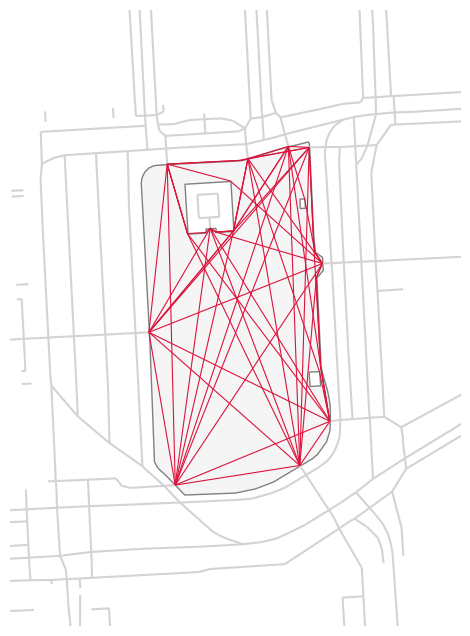

In [2]:
# The outline of the square, with the hole in it
areas = osm.get_data_by_custom_criteria({"highway": ["pedestrian"]}, keep_nodes=False)
outline = areas[(areas["osm_type"] == "relation") & (areas["id"] == 2919118)]

ax = outline.plot(color="whitesmoke", edgecolor="gray", figsize=(8, 8))
edges[~edges["walking_area"]].plot(ax=ax, color="lightgray")
square.plot(ax=ax, color="crimson", linewidth=0.8)
xmin, ymin, xmax, ymax = outline.total_bounds
ax.set_xlim(xmin - 0.001, xmax + 0.001)
ax.set_ylim(ymin - 0.0005, ymax + 0.0005)
ax.set_axis_off()

In a graph, `walking_area` is an attribute of each edge, so routing can tell the edges across walking areas apart, for example to leave them out. Simplifying the graph never merges such an edge with another one. Below, we compare the shortest route between the two ends of the longest edge across the square with and without the edges across walking areas:

In [3]:
import networkx as nx

G = osm.get_graph("walking", graph_type="networkx", walking_areas=True)
source, target = square.loc[square["length"].idxmax(), ["u", "v"]]

# The graph without the edges across walking areas
streets = G.copy()
streets.remove_edges_from(
    [(u, v, k) for u, v, k, data in G.edges(keys=True, data=True) if data["walking_area"]]
)

across = nx.shortest_path_length(G, source, target, weight="length")
around = nx.shortest_path_length(streets, source, target, weight="length")
print("Across the square: %.0f m" % across)
print("Without walking areas: %.0f m" % around)

Across the square: 154 m
Without walking areas: 222 m


An edge across a walking area counts its length, like an edge along a street, as in the two studies above. Here the route across the square is 68 m shorter than the one without walking areas.

With `walking_areas=True`, `get_graph()` builds the graph from the tables of `get_network(nodes=True)`, also with the out-of-core engine, so it needs as much memory as reading the network with its nodes.

With `indoor_elements=True`, a network also gets lines across platform areas and indoor corridors. These lines are on each area's own level. The page [Indoor passages and platforms](indoor_networks.ipynb) shows them in two London stations.